# Thí nghiệm 4: bài lớn, GA P1/P2 và trade-off ngân sách

Thay các vòng “chạy đến khi đạt target” của notebook cũ bằng finite evaluation budgets.


**Cách chạy:** từ root cài `python -m pip install -r requirements.txt`, mở
`jupyter notebook`, chọn kernel/interpreter `.venv` vừa cài rồi **Restart Kernel & Run All**.
Trong VS Code, dùng **Select Kernel → Python Environments → .venv**. Nếu import lỗi,
kiểm tra kernel; không sửa sys.path. Notebook nhận diện root khi mở từ root hoặc `Experiment/`.

Quick mặc định dùng 5 seed cố định, run count và objective budget hữu hạn; Full là opt-in 25 seed.
Mỗi run có cooperative time cap và tổng solver time cap (không phải hard real-time).
Không ghi raw output ra file hay lặp đến khi đạt một nghiệm mong muốn. Chạy lại từ đầu để reset biến.
Chi phí là đơn vị của ma trận, không mặc định km. Cả 7 file có `known_optimum=None`;
không dùng hậu tố filename làm optimum/gap đã chứng minh.


In [1]:
from pathlib import Path
from dataclasses import replace
import json
import math
import platform
import statistics
from time import perf_counter
from IPython import get_ipython
from IPython.display import display, Markdown
import matplotlib.pyplot as plt

from ga_eho_tsp import __version__
from ga_eho_tsp.algorithms.ga import solve
from ga_eho_tsp.data.matrix_loader import load_matrix
from ga_eho_tsp.domain.models import GAConfig
from ga_eho_tsp.domain.objective import validate_route

get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi': 85, 'font.size': 9})
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'pyproject.toml').is_file() and (p / 'data/legacy').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Hãy mở Jupyter từ root dự án hoặc Experiment/.')

MODE = 'QUICK'  # Đổi thành FULL rồi Restart Kernel & Run All để dùng 25 seed.
assert MODE in {'QUICK', 'FULL'}
SEEDS = [11, 23, 37, 53, 71] if MODE == 'QUICK' else list(range(101, 126))
SOLVER_SECONDS_LIMIT = 120.0 if MODE == 'QUICK' else 600.0
MAX_RUNS = 150 if MODE == 'QUICK' else 1200
RUN_COUNT, SOLVER_SECONDS = 0, 0.0
SESSION_START = perf_counter()

def checked_solve(problem, config):
    global RUN_COUNT, SOLVER_SECONDS
    remaining = SOLVER_SECONDS_LIMIT - SOLVER_SECONDS
    if RUN_COUNT >= MAX_RUNS or remaining <= 0:
        raise RuntimeError('Vượt hạn mức notebook; không coi batch thiếu là đã hoàn thành.')
    config = replace(config, time_limit_seconds=min(5.0 if MODE == 'QUICK' else 15.0, remaining))
    result = solve(problem, config)
    RUN_COUNT += 1
    SOLVER_SECONDS += result.elapsed_seconds
    validate_route(result.best_route, problem.dimension)
    independent_cost = sum(problem.distance_matrix[result.best_route[i]][
        result.best_route[(i + 1) % problem.dimension]] for i in range(problem.dimension))
    assert math.isclose(result.best_distance, independent_cost, rel_tol=1e-12, abs_tol=1e-9)
    assert result.is_valid and result.evaluations <= config.max_evaluations
    assert result.history[0].iteration == 0
    assert result.history[-1].evaluations == result.evaluations
    assert all(b.best_so_far <= a.best_so_far for a, b in zip(result.history, result.history[1:]))
    assert result.metadata['local_search_full_evaluations'] <= result.evaluations
    return result

def show_table(headers, rows):
    text = '| ' + ' | '.join(headers) + ' |\n'
    text += '| ' + ' | '.join(['---'] * len(headers)) + ' |\n'
    text += '\n'.join('| ' + ' | '.join(map(str, row)) + ' |' for row in rows)
    display(Markdown(text))

print(f'Python {platform.python_version()} | ga_eho_tsp {__version__} | {MODE} | seeds={SEEDS}')


Python 3.11.9 | ga_eho_tsp 0.2.0 | QUICK | seeds=[11, 23, 37, 53, 71]


## Câu hỏi và giả thuyết
Trên15/26/42/48city, PMX và NN/mixed có giúp hơn control dưới cùng full-objective budget không?
Adaptive và 2-opt có thể kém control: local probes tiêu thụ budget, làm giảm số offspring/generations.
Thiết kế mỗi lần đổi một yếu tố, cùng seeds/P40/elites2/budget4000 ở Quick.
NN lookup work nằm trong runtime; không phải objective call. Runtime không bao gồm loader/plot/validation bên ngoài.


In [2]:
DATASETS = ['15Cities-1194.txt', '26Cities-937.txt', '42Cities-699.txt', '48Cities-33523.txt']
BUDGET = 4000 if MODE == 'QUICK' else 12000
BASE = GAConfig(population_size=40 if MODE == 'QUICK' else 80,
                generations=4000, max_iterations=4000, max_evaluations=BUDGET)
changes = {'control': {}, 'PMX': {'crossover_method': 'pmx'},
           'mixed25%': {'initialization_method': 'mixed'},
           'NN': {'initialization_method': 'nearest_neighbor'},
           'adaptive': {'adaptive_mutation': True},
           'GA+2-opt': {'local_search_enabled': True, 'local_search_max_moves': 1,
                        'local_search_max_probes': 10}}
if MODE == 'FULL':
    changes['adaptive+2-opt'] = {**changes['GA+2-opt'], 'adaptive_mutation': True}
problems = {name: load_matrix(ROOT/'data/legacy'/name) for name in DATASETS}
print(f'{len(DATASETS)} datasets × {len(changes)} variants × {len(SEEDS)} seeds; budget={BUDGET}')


4 datasets × 6 variants × 5 seeds; budget=4000


In [3]:
all_runs = {}
for dataset, problem in problems.items():
    all_runs[dataset] = {}
    for variant, override in changes.items():
        all_runs[dataset][variant] = [checked_solve(problem, replace(BASE, seed=seed, **override)) for seed in SEEDS]


In [4]:
deep_summary, rows = {}, []
for dataset, variants in all_runs.items():
    deep_summary[dataset] = {}
    for variant, runs in variants.items():
        distances = [r.best_distance for r in runs]
        s = {'mean': statistics.mean(distances), 'median': statistics.median(distances),
             'std': statistics.stdev(distances), 'min': min(distances), 'max': max(distances),
             'evaluations_min': min(r.evaluations for r in runs),
             'evaluations_max': max(r.evaluations for r in runs),
             'runtime_mean': statistics.mean(r.elapsed_seconds for r in runs),
             'iterations_mean': statistics.mean(r.iterations_completed for r in runs),
             'local_calls_mean': statistics.mean(r.metadata['local_search_full_evaluations'] for r in runs)}
        deep_summary[dataset][variant] = s
        rows.append([problems[dataset].dimension, variant, f"{s['mean']:.2f}", f"{s['median']:.2f}",
                     f"{s['std']:.2f}", f"{s['evaluations_min']}–{s['evaluations_max']}",
                     f"{s['runtime_mean']:.4f}", f"{s['iterations_mean']:.1f}", f"{s['local_calls_mean']:.1f}"])
show_table(['n', 'Variant', 'Mean cost', 'Median', 'Sample std', 'Actual eval',
            'Runtime mean(s)', 'Committed gen mean', 'Full local calls mean'], rows)


| n | Variant | Mean cost | Median | Sample std | Actual eval | Runtime mean(s) | Committed gen mean | Full local calls mean |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 15 | control | 1200.20 | 1194.00 | 13.86 | 4000–4000 | 0.0495 | 104.0 | 0.0 |
| 15 | PMX | 1219.20 | 1194.00 | 41.26 | 4000–4000 | 0.0430 | 104.0 | 0.0 |
| 15 | mixed25% | 1194.00 | 1194.00 | 0.00 | 4000–4000 | 0.0451 | 104.0 | 0.0 |
| 15 | NN | 1194.00 | 1194.00 | 0.00 | 4000–4000 | 0.0501 | 104.0 | 0.0 |
| 15 | adaptive | 1228.00 | 1225.00 | 44.18 | 4000–4000 | 0.0485 | 104.0 | 0.0 |
| 15 | GA+2-opt | 1336.20 | 1327.00 | 20.68 | 4000–4000 | 0.0236 | 15.0 | 3370.2 |
| 26 | control | 1046.00 | 1034.00 | 82.85 | 4000–4000 | 0.0560 | 104.0 | 0.0 |
| 26 | PMX | 1054.00 | 1052.00 | 45.18 | 4000–4000 | 0.0531 | 104.0 | 0.0 |
| 26 | mixed25% | 958.60 | 961.00 | 3.29 | 4000–4000 | 0.0554 | 104.0 | 0.0 |
| 26 | NN | 961.80 | 961.00 | 1.79 | 4000–4000 | 0.0563 | 104.0 | 0.0 |
| 26 | adaptive | 1016.40 | 1031.00 | 41.56 | 4000–4000 | 0.0564 | 104.0 | 0.0 |
| 26 | GA+2-opt | 1388.80 | 1422.00 | 86.50 | 4000–4000 | 0.0320 | 17.0 | 3285.6 |
| 42 | control | 1151.60 | 1133.00 | 49.75 | 4000–4000 | 0.0690 | 104.0 | 0.0 |
| 42 | PMX | 1114.80 | 1131.00 | 88.48 | 4000–4000 | 0.0657 | 104.0 | 0.0 |
| 42 | mixed25% | 811.80 | 815.00 | 35.73 | 4000–4000 | 0.0691 | 104.0 | 0.0 |
| 42 | NN | 782.20 | 781.00 | 13.81 | 4000–4000 | 0.0711 | 104.0 | 0.0 |
| 42 | adaptive | 1112.40 | 1083.00 | 87.13 | 4000–4000 | 0.0698 | 104.0 | 0.0 |
| 42 | GA+2-opt | 1750.20 | 1725.00 | 85.99 | 4000–4000 | 0.0423 | 17.4 | 3282.8 |
| 48 | control | 55404.60 | 55339.00 | 3031.79 | 4000–4000 | 0.0750 | 104.0 | 0.0 |
| 48 | PMX | 55073.20 | 52736.00 | 5420.82 | 4000–4000 | 0.0723 | 104.0 | 0.0 |
| 48 | mixed25% | 37222.20 | 36972.00 | 873.02 | 4000–4000 | 0.0764 | 104.0 | 0.0 |
| 48 | NN | 36559.00 | 36591.00 | 497.05 | 4000–4000 | 0.0780 | 104.0 | 0.0 |
| 48 | adaptive | 53912.20 | 54467.00 | 3030.98 | 4000–4000 | 0.0767 | 104.0 | 0.0 |
| 48 | GA+2-opt | 81489.60 | 78245.00 | 7467.46 | 4000–4000 | 0.0482 | 20.6 | 3163.4 |

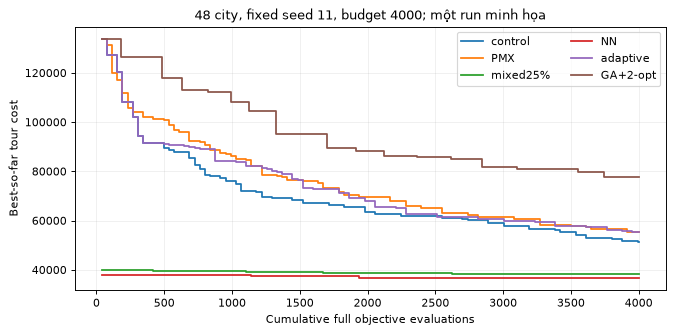

In [5]:
selected_dataset = DATASETS[-1]
fig, ax = plt.subplots(figsize=(8, 4))
for name, runs in all_runs[selected_dataset].items():
    history = runs[0].history
    ax.step([s.evaluations for s in history], [s.best_so_far for s in history], where='post', label=name)
ax.set(title=f'48 city, fixed seed {SEEDS[0]}, budget {BUDGET}; một run minh họa',
       xlabel='Cumulative full objective evaluations', ylabel='Best-so-far tour cost')
ax.legend(ncol=2); ax.grid(alpha=.2)
fig.tight_layout(); plt.show(); plt.close(fig)


## Minh họa dữ liệu và route
Không có coordinates: heatmap dưới là **ma trận chi phí**, không phải bản đồ đường phố/GPS.
Route minh họa lấy mixed seed đầu cố định; đóng0 chỉ ở display. Không chọn run tốt nhất để quảng cáo.


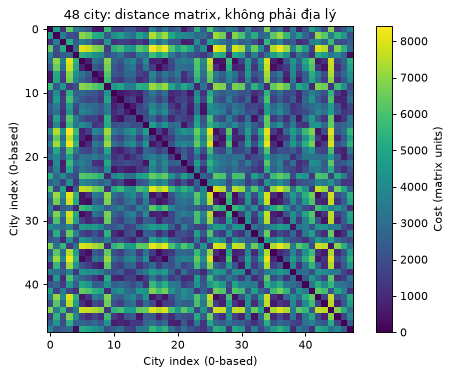

**Tour đóng vòng để hiển thị:** 0 → 21 → 15 → 2 → 33 → 40 → 1 → 28 → 25 → 3 → 34 → 44 → 23 → 9 → 41 → 4 → 47 → 38 → 31 → 20 → 46 → 10 → 22 → 13 → 24 → 12 → 11 → 19 → 5 → 36 → 18 → 16 → 42 → 26 → 29 → 35 → 27 → 6 → 17 → 43 → 45 → 32 → 14 → 39 → 8 → 7 → 37 → 30 → 0

Cost kiểm tra lại=38553; seed=11; status=MAX_EVALUATIONS


In [6]:
problem = problems[selected_dataset]
example = all_runs[selected_dataset]['mixed25%'][0]
fig, ax = plt.subplots(figsize=(6, 4.5))
image = ax.imshow(problem.distance_matrix, cmap='viridis')
ax.set(xlabel='City index (0-based)', ylabel='City index (0-based)', title='48 city: distance matrix, không phải địa lý')
fig.colorbar(image, ax=ax, label='Cost (matrix units)')
fig.tight_layout(); plt.show(); plt.close(fig)
display(Markdown('**Tour đóng vòng để hiển thị:** ' + ' → '.join(map(str, (*example.best_route, 0)))))
print(f'Cost kiểm tra lại={problem.route_length(example.best_route):g}; seed={example.seed}; status={example.stopping_reason}')


## Accounting và failure cases
Mỗi probe 2-opt dùng FULL objective và nằm trong total evaluations, kể cả bị reject.
Không có delta probes/cache ẩn. Cùng evaluation budget không có nghĩa cùng thời gian hoặc cùng số generations.
Giữ cả trường hợp 2-opt thua control. Partial generation vẫn có archive của probe tốt nhưng stats là population commit.


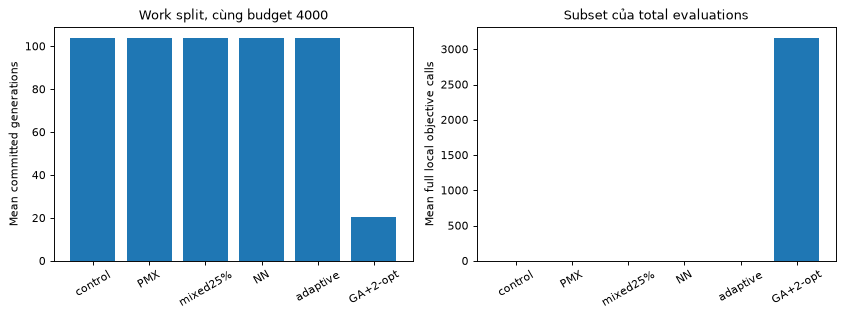

In [7]:
large = deep_summary[selected_dataset]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
names = list(large)
axes[0].bar(names, [large[n]['iterations_mean'] for n in names])
axes[0].set(ylabel='Mean committed generations', title=f'Work split, cùng budget {BUDGET}')
axes[1].bar(names, [large[n]['local_calls_mean'] for n in names])
axes[1].set(ylabel='Mean full local objective calls', title='Subset của total evaluations')
for ax in axes: ax.tick_params(axis='x', rotation=30)
fig.tight_layout(); plt.show(); plt.close(fig)


## Kết luận và khuyến nghị theo dữ liệu
Các câu dưới tự cập nhật từ kết quả, kể cả kết quả âm.


In [8]:
observations = []
for dataset, summaries in deep_summary.items():
    best_variant = min(summaries, key=lambda name: summaries[name]['mean'])
    delta = summaries['GA+2-opt']['mean'] - summaries['control']['mean']
    observations.append(f"- {problems[dataset].dimension} city: mean nhỏ nhất là **{best_variant}** "
        f"({summaries[best_variant]['mean']:.2f}); 2-opt {'kém hơn' if delta>0 else 'tốt hơn' if delta<0 else 'bằng'} "
        f"control về mean, chênh={delta:+.2f} đơn vị ma trận.")
display(Markdown('\n'.join(observations)))
display(Markdown('Giữ random/tournament/OX/inversion làm baseline công bằng để bàn giao EHO. '
    'NN/mixed/adaptive/2-opt là biến thể opt-in; không chọn default chỉ từ một instance hoặc5seed. '
    'Đường hội tụ seed đầu chỉ minh họa; bảng nhiều seed mới là cơ sở nhận xét. '
    'Bottleneck theo lịch sử profiling là objective validation/OX; phiên notebook này không đo speedup trước/sau. '
    'Chưa kiểm định thống kê rộng, chưa có optimum/provenance cho bài lớn, EHO và GUI chưa triển khai.'))
NOTEBOOK_REPORT = {'notebook': 'Experiment 4', 'mode': MODE, 'seeds': SEEDS, 'runs': RUN_COUNT,
    'budget': BUDGET, 'solver_seconds': SOLVER_SECONDS, 'deep': deep_summary,
    'wall_seconds': perf_counter()-SESSION_START}
print(f'Hoàn thành {RUN_COUNT} run; solver time={SOLVER_SECONDS:.3f}s; giữ nguyên mọi kết quả âm.')


- 15 city: mean nhỏ nhất là **mixed25%** (1194.00); 2-opt kém hơn control về mean, chênh=+136.00 đơn vị ma trận.
- 26 city: mean nhỏ nhất là **mixed25%** (958.60); 2-opt kém hơn control về mean, chênh=+342.80 đơn vị ma trận.
- 42 city: mean nhỏ nhất là **NN** (782.20); 2-opt kém hơn control về mean, chênh=+598.60 đơn vị ma trận.
- 48 city: mean nhỏ nhất là **NN** (36559.00); 2-opt kém hơn control về mean, chênh=+26085.00 đơn vị ma trận.

Giữ random/tournament/OX/inversion làm baseline công bằng để bàn giao EHO. NN/mixed/adaptive/2-opt là biến thể opt-in; không chọn default chỉ từ một instance hoặc5seed. Đường hội tụ seed đầu chỉ minh họa; bảng nhiều seed mới là cơ sở nhận xét. Bottleneck theo lịch sử profiling là objective validation/OX; phiên notebook này không đo speedup trước/sau. Chưa kiểm định thống kê rộng, chưa có optimum/provenance cho bài lớn, EHO và GUI chưa triển khai.

Hoàn thành 120 run; solver time=6.913s; giữ nguyên mọi kết quả âm.
